# DWML Mini Ptoject on Clustering
### `Name: Shreeya Tapaswi`
### `Roll No - 31474`

# Customer Segmentation using Clustering Techniques
### Mini Project – Data Mining / Machine Learning
**Dataset:** Mall Customer Segmentation Data (Kaggle, 200 real customers)

**Problem statement:** A shopping mall wants to understand its customers. Using each customer's **Annual Income** and **Spending Score**, we group customers into meaningful segments with different clustering algorithms, evaluate the results, detect abnormal customers (outliers) and suggest a marketing strategy for each segment.

**Syllabus coverage**

| Syllabus topic | What is done in this notebook |
|---|---|
| Partitioning methods | K-Means, K-Medoids (implemented from scratch) |
| Hierarchical methods | Agglomerative clustering, linkage comparison, dendrogram |
| Density-based methods | DBSCAN, OPTICS |
| Evaluation | Clustering tendency (Hopkins), internal indices, stability, agreement between methods |
| Outlier detection methods | Statistical, distance/clustering-based, density-based, isolation-based |

**Contents:** 1 Setup · 2 Load data · 3 EDA · 4 Preprocessing & tendency · 5 Partitioning · 6 Hierarchical · 7 Density-based · 8 Evaluation · 9 Outlier detection · 10 Final model · 11 Business insights · 12 Conclusion


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score, pairwise_distances)
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist
from scipy.stats import chi2

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
np.random.seed(42)

## 2. Load the Real Dataset
The Kaggle **Mall Customers** dataset has 200 rows: `CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`.

The cell below downloads it from a public GitHub mirror. **If you downloaded it from Kaggle yourself**, upload `Mall_Customers.csv` to Colab (folder icon on the left) and change the path to `pd.read_csv('Mall_Customers.csv')`. A built-in backup copy is used automatically if there is no internet.

In [2]:
URL = 'https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/master/Chapter03/Datasets/Mall_Customers.csv'
try:
    df = pd.read_csv(URL)          # or: pd.read_csv('Mall_Customers.csv') for your own uploaded copy
    print('Loaded from URL')
except Exception as e:
    df = None
    print('Could not download, backup copy will be used in the next cell.')

Loaded from URL


In [3]:
# Backup copy of the dataset (only used if the download above failed)
if df is None:
    from io import StringIO
    BACKUP = '''CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
1,Male,19,15,39
2,Male,21,15,81
3,Female,20,16,6
4,Female,23,16,77
5,Female,31,17,40
6,Female,22,17,76
7,Female,35,18,6
8,Female,23,18,94
9,Male,64,19,3
10,Female,30,19,72
11,Male,67,19,14
12,Female,35,19,99
13,Female,58,20,15
14,Female,24,20,77
15,Male,37,20,13
16,Male,22,20,79
17,Female,35,21,35
18,Male,20,21,66
19,Male,52,23,29
20,Female,35,23,98
21,Male,35,24,35
22,Male,25,24,73
23,Female,46,25,5
24,Male,31,25,73
25,Female,54,28,14
26,Male,29,28,82
27,Female,45,28,32
28,Male,35,28,61
29,Female,40,29,31
30,Female,23,29,87
31,Male,60,30,4
32,Female,21,30,73
33,Male,53,33,4
34,Male,18,33,92
35,Female,49,33,14
36,Female,21,33,81
37,Female,42,34,17
38,Female,30,34,73
39,Female,36,37,26
40,Female,20,37,75
41,Female,65,38,35
42,Male,24,38,92
43,Male,48,39,36
44,Female,31,39,61
45,Female,49,39,28
46,Female,24,39,65
47,Female,50,40,55
48,Female,27,40,47
49,Female,29,40,42
50,Female,31,40,42
51,Female,49,42,52
52,Male,33,42,60
53,Female,31,43,54
54,Male,59,43,60
55,Female,50,43,45
56,Male,47,43,41
57,Female,51,44,50
58,Male,69,44,46
59,Female,27,46,51
60,Male,53,46,46
61,Male,70,46,56
62,Male,19,46,55
63,Female,67,47,52
64,Female,54,47,59
65,Male,63,48,51
66,Male,18,48,59
67,Female,43,48,50
68,Female,68,48,48
69,Male,19,48,59
70,Female,32,48,47
71,Male,70,49,55
72,Female,47,49,42
73,Female,60,50,49
74,Female,60,50,56
75,Male,59,54,47
76,Male,26,54,54
77,Female,45,54,53
78,Male,40,54,48
79,Female,23,54,52
80,Female,49,54,42
81,Male,57,54,51
82,Male,38,54,55
83,Male,67,54,41
84,Female,46,54,44
85,Female,21,54,57
86,Male,48,54,46
87,Female,55,57,58
88,Female,22,57,55
89,Female,34,58,60
90,Female,50,58,46
91,Female,68,59,55
92,Male,18,59,41
93,Male,48,60,49
94,Female,40,60,40
95,Female,32,60,42
96,Male,24,60,52
97,Female,47,60,47
98,Female,27,60,50
99,Male,48,61,42
100,Male,20,61,49
101,Female,23,62,41
102,Female,49,62,48
103,Male,67,62,59
104,Male,26,62,55
105,Male,49,62,56
106,Female,21,62,42
107,Female,66,63,50
108,Male,54,63,46
109,Male,68,63,43
110,Male,66,63,48
111,Male,65,63,52
112,Female,19,63,54
113,Female,38,64,42
114,Male,19,64,46
115,Female,18,65,48
116,Female,19,65,50
117,Female,63,65,43
118,Female,49,65,59
119,Female,51,67,43
120,Female,50,67,57
121,Male,27,67,56
122,Female,38,67,40
123,Female,40,69,58
124,Male,39,69,91
125,Female,23,70,29
126,Female,31,70,77
127,Male,43,71,35
128,Male,40,71,95
129,Male,59,71,11
130,Male,38,71,75
131,Male,47,71,9
132,Male,39,71,75
133,Female,25,72,34
134,Female,31,72,71
135,Male,20,73,5
136,Female,29,73,88
137,Female,44,73,7
138,Male,32,73,73
139,Male,19,74,10
140,Female,35,74,72
141,Female,57,75,5
142,Male,32,75,93
143,Female,28,76,40
144,Female,32,76,87
145,Male,25,77,12
146,Male,28,77,97
147,Male,48,77,36
148,Female,32,77,74
149,Female,34,78,22
150,Male,34,78,90
151,Male,43,78,17
152,Male,39,78,88
153,Female,44,78,20
154,Female,38,78,76
155,Female,47,78,16
156,Female,27,78,89
157,Male,37,78,1
158,Female,30,78,78
159,Male,34,78,1
160,Female,30,78,73
161,Female,56,79,35
162,Female,29,79,83
163,Male,19,81,5
164,Female,31,81,93
165,Male,50,85,26
166,Female,36,85,75
167,Male,42,86,20
168,Female,33,86,95
169,Female,36,87,27
170,Male,32,87,63
171,Male,40,87,13
172,Male,28,87,75
173,Male,36,87,10
174,Male,36,87,92
175,Female,52,88,13
176,Female,30,88,86
177,Male,58,88,15
178,Male,27,88,69
179,Male,59,93,14
180,Male,35,93,90
181,Female,37,97,32
182,Female,32,97,86
183,Male,46,98,15
184,Female,29,98,88
185,Female,41,99,39
186,Male,30,99,97
187,Female,54,101,24
188,Male,28,101,68
189,Female,41,103,17
190,Female,36,103,85
191,Female,34,103,23
192,Female,32,103,69
193,Male,33,113,8
194,Female,38,113,91
195,Female,47,120,16
196,Female,35,120,79
197,Female,45,126,28
198,Male,32,126,74
199,Male,32,137,18
200,Male,30,137,83'''
    df = pd.read_csv(StringIO(BACKUP))
    print('Loaded from built-in backup')

df = df.rename(columns={'Annual Income (k$)': 'Annual_Income', 'Spending Score (1-100)': 'Spending_Score', 'Genre': 'Gender'})
df.head(10)

,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


## 3. Exploratory Data Analysis

In [4]:
print('Shape:', df.shape)
print('Missing values:', int(df.isnull().sum().sum()), '| Duplicates:', int(df.duplicated().sum()))
df.info()
df[['Age', 'Annual_Income', 'Spending_Score']].describe()

Shape: (200, 5)
Missing values: 0 | Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      200 non-null    int64 
 1   Gender          200 non-null    object
 2   Age             200 non-null    int64 
 3   Annual_Income   200 non-null    int64 
 4   Spending_Score  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,Age,Annual_Income,Spending_Score
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


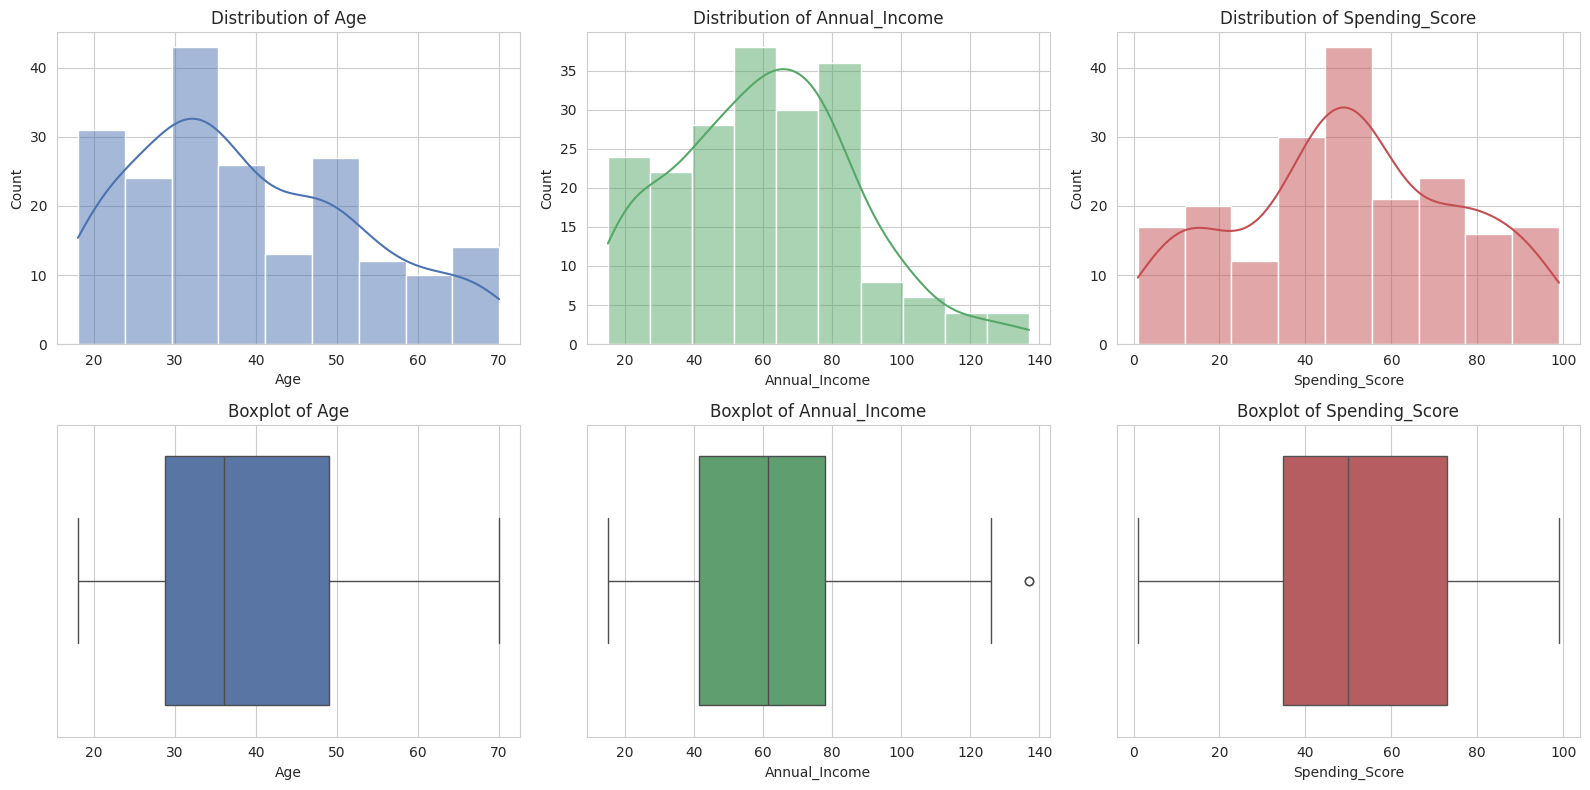

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (col, c) in enumerate(zip(['Age', 'Annual_Income', 'Spending_Score'], ['#4C72B0', '#55A868', '#C44E52'])):
    sns.histplot(df[col], kde=True, ax=ax[0, i], color=c); ax[0, i].set_title(f'Distribution of {col}')
    sns.boxplot(x=df[col], ax=ax[1, i], color=c);          ax[1, i].set_title(f'Boxplot of {col}')
plt.tight_layout(); plt.show()

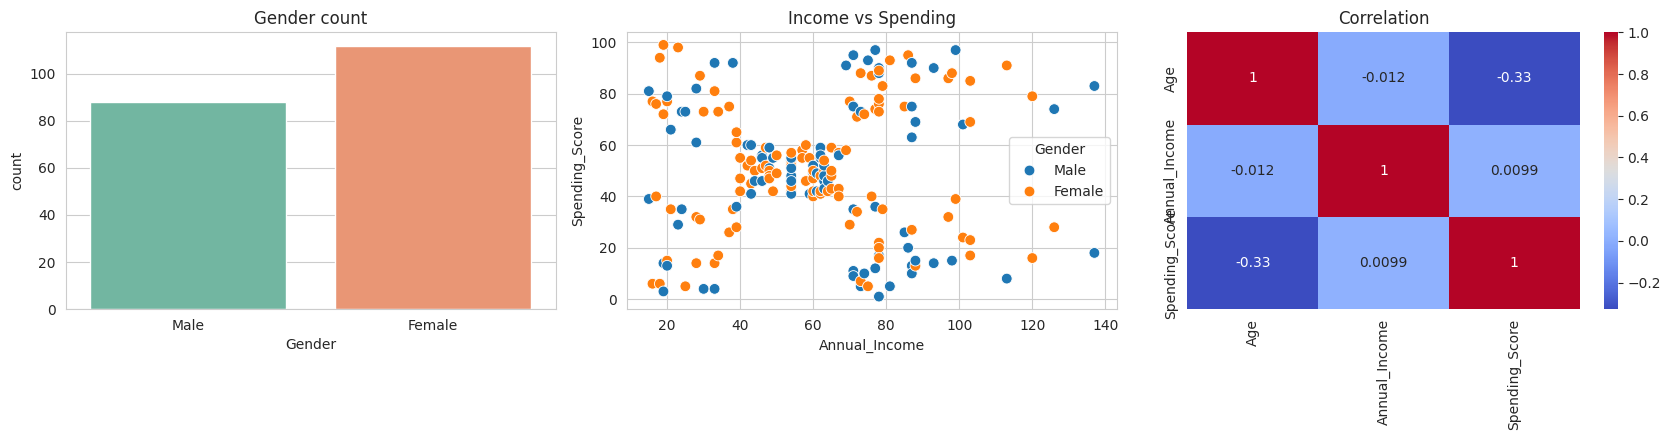

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(x='Gender', data=df, palette='Set2', ax=ax[0]); ax[0].set_title('Gender count')
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Gender', data=df, s=60, ax=ax[1]); ax[1].set_title('Income vs Spending')
sns.heatmap(df[['Age', 'Annual_Income', 'Spending_Score']].corr(), annot=True, cmap='coolwarm', ax=ax[2]); ax[2].set_title('Correlation')
plt.tight_layout(); plt.show()

**Observations:** the data is clean (no missing values). Income and Spending Score are almost uncorrelated, and the scatter plot already hints at several natural groups, which is exactly what clustering should uncover. Gender does not separate the groups, so we will use it only for profiling later.

## 4. Preprocessing and Clustering Tendency
We cluster on **Annual Income** and **Spending Score** (the classic mall-segmentation setup, easy to visualise in 2D). Age and Gender are used later to *describe* the segments. Features are standardised because clustering is distance-based.

The **Hopkins statistic** checks whether the data really has cluster structure *before* clustering: H ≈ 0.5 means random data, H > 0.75 means strong tendency.

In [7]:
features = ['Annual_Income', 'Spending_Score']
scaler = StandardScaler()
X = scaler.fit_transform(df[features])

def hopkins(X, frac=0.15, seed=42):
    r = np.random.default_rng(seed)
    n, d = X.shape; m = int(frac * n)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    idx = r.choice(n, m, replace=False)
    w = nn.kneighbors(X[idx], 2)[0][:, 1]                  # real point -> nearest other real point
    U = r.uniform(X.min(0), X.max(0), (m, d))
    u = nn.kneighbors(U, 1)[0][:, 0]                       # random point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

H = np.mean([hopkins(X, seed=s) for s in range(10)])
verdict = 'strong clustering tendency' if H > 0.75 else ('moderate clustering tendency' if H > 0.6 else 'weak / random')
print(f'Hopkins statistic = {H:.3f}  ->', verdict)

Hopkins statistic = 0.693  -> moderate clustering tendency


## 5. Partitioning Methods
Partitioning methods split the data into **K** groups; each point belongs to exactly one cluster.
- **K-Means** – each cluster is represented by its *mean* (centroid). Fast, but sensitive to outliers.
- **K-Medoids (PAM-style)** – each cluster is represented by an actual data point (*medoid*). More robust to outliers.

### 5.1 Choosing K

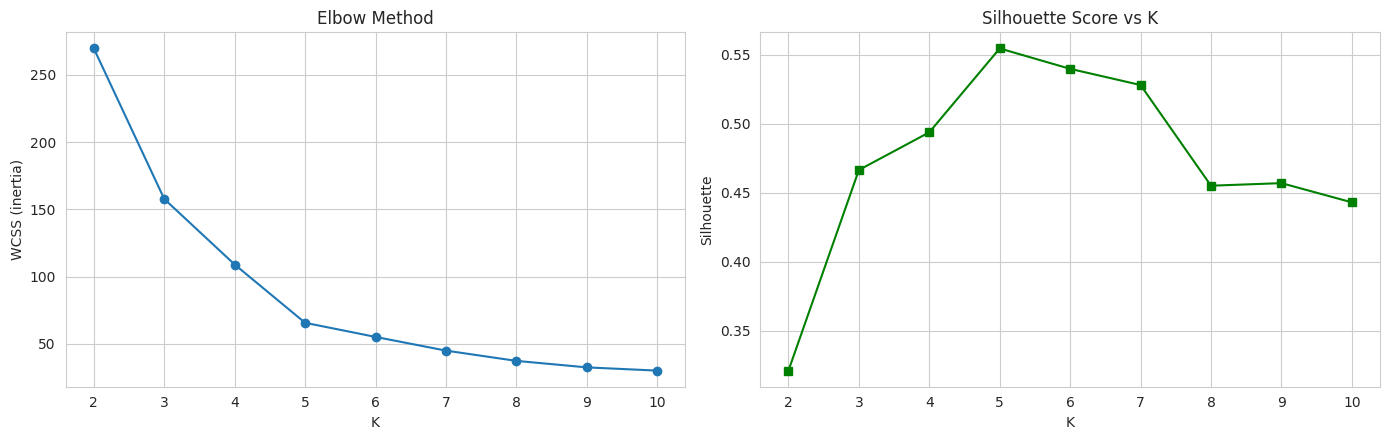

Highest silhouette at K = 5


In [8]:
K_range = range(2, 11)
wcss, sil = [], []
for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42).fit(X)
    wcss.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(K_range, wcss, 'o-'); ax[0].set(title='Elbow Method', xlabel='K', ylabel='WCSS (inertia)')
ax[1].plot(K_range, sil, 's-', color='green'); ax[1].set(title='Silhouette Score vs K', xlabel='K', ylabel='Silhouette')
plt.tight_layout(); plt.show()
print('Highest silhouette at K =', list(K_range)[int(np.argmax(sil))])

The elbow bends at **K = 5** and the silhouette score is also high there (the dendrogram in Section 6 agrees), so we use K = 5. Change `K` to experiment.

In [9]:
K = 5

# ---- K-Means
kmeans = KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=42)
df['KMeans'] = kmeans.fit_predict(X)

# ---- K-Medoids (alternating / Voronoi-iteration version of PAM, written from scratch)
def kmedoids(X, k, n_init=10, max_iter=100, seed=42):
    D = pairwise_distances(X)
    r = np.random.default_rng(seed)
    best = (np.inf, None, None)
    for _ in range(n_init):
        medoids = r.choice(len(X), k, replace=False)
        for _ in range(max_iter):
            labels = np.argmin(D[:, medoids], axis=1)
            new = medoids.copy()
            for c in range(k):
                members = np.where(labels == c)[0]
                if len(members):
                    new[c] = members[np.argmin(D[np.ix_(members, members)].sum(axis=1))]
            if np.array_equal(new, medoids): break
            medoids = new
        labels = np.argmin(D[:, medoids], axis=1)
        cost = D[np.arange(len(X)), medoids[labels]].sum()
        if cost < best[0]: best = (cost, labels, medoids)
    return best[1], best[2], best[0]

labels_med, medoid_idx, cost = kmedoids(X, K)
df['KMedoids'] = labels_med
print('K-Medoids total cost:', round(cost, 2))
print('K-Means   sizes:', df['KMeans'].value_counts().sort_index().to_dict())
print('K-Medoids sizes:', df['KMedoids'].value_counts().sort_index().to_dict())

K-Medoids total cost: 101.89
K-Means   sizes: {0: 81, 1: 39, 2: 22, 3: 35, 4: 23}
K-Medoids sizes: {0: 35, 1: 21, 2: 25, 3: 80, 4: 39}


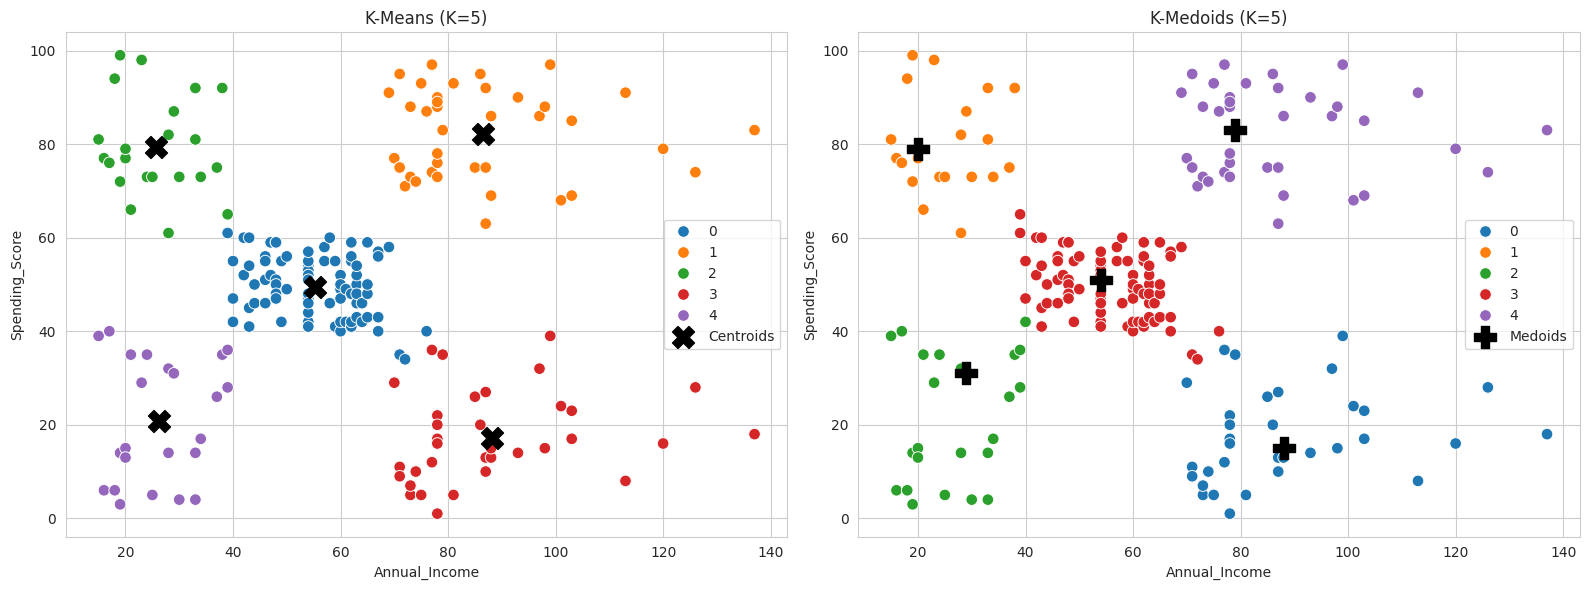

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMeans', data=df, palette='tab10', s=70, ax=ax[0])
c = scaler.inverse_transform(kmeans.cluster_centers_)
ax[0].scatter(c[:, 0], c[:, 1], c='black', marker='X', s=250, label='Centroids'); ax[0].set_title(f'K-Means (K={K})'); ax[0].legend()

sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='KMedoids', data=df, palette='tab10', s=70, ax=ax[1])
m = df.iloc[medoid_idx]
ax[1].scatter(m['Annual_Income'], m['Spending_Score'], c='black', marker='P', s=250, label='Medoids'); ax[1].set_title(f'K-Medoids (K={K})'); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Hierarchical Methods
Agglomerative clustering starts with every point as its own cluster and repeatedly merges the two closest clusters. The result is a tree called a **dendrogram**.

### 6.1 Comparing linkage criteria
The **cophenetic correlation** measures how well the dendrogram preserves the original pairwise distances (closer to 1 = better).

In [11]:
rows = []
for link in ['single', 'complete', 'average', 'ward']:
    Z = linkage(X, method=link)
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(X)
    rows.append({'Linkage': link, 'Cophenetic corr.': round(cophenet(Z, pdist(X))[0], 3),
                 'Silhouette': round(silhouette_score(X, lab), 3),
                 'Cluster sizes': sorted(np.bincount(lab), reverse=True)})
pd.DataFrame(rows)

,Linkage,Cophenetic corr.,Silhouette,Cluster sizes
0,single,0.722,0.276,"[195, 2, 1, 1, 1]"
1,complete,0.667,0.553,"[79, 39, 38, 23, 21]"
2,average,0.722,0.479,"[102, 38, 36, 21, 3]"
3,ward,0.721,0.554,"[85, 39, 32, 23, 21]"


Single linkage shows the *chaining effect* (one huge cluster and tiny leftovers). **Ward** linkage gives compact, balanced clusters, so we use it.

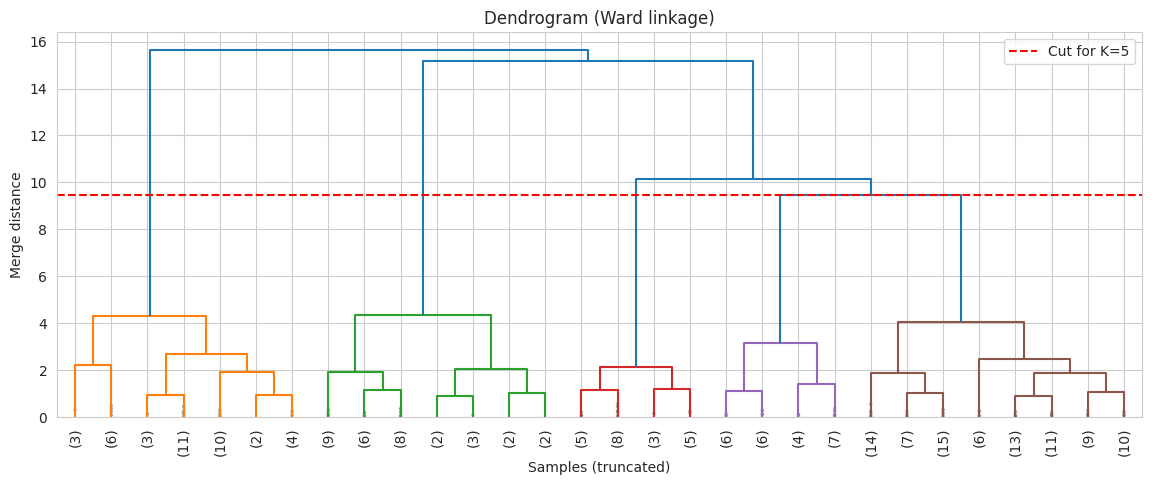

In [12]:
Z = linkage(X, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, show_contracted=True, color_threshold=Z[-(K-1), 2])
plt.axhline(Z[-(K-1), 2], color='red', ls='--', label=f'Cut for K={K}')
plt.title('Dendrogram (Ward linkage)'); plt.xlabel('Samples (truncated)'); plt.ylabel('Merge distance'); plt.legend(); plt.show()

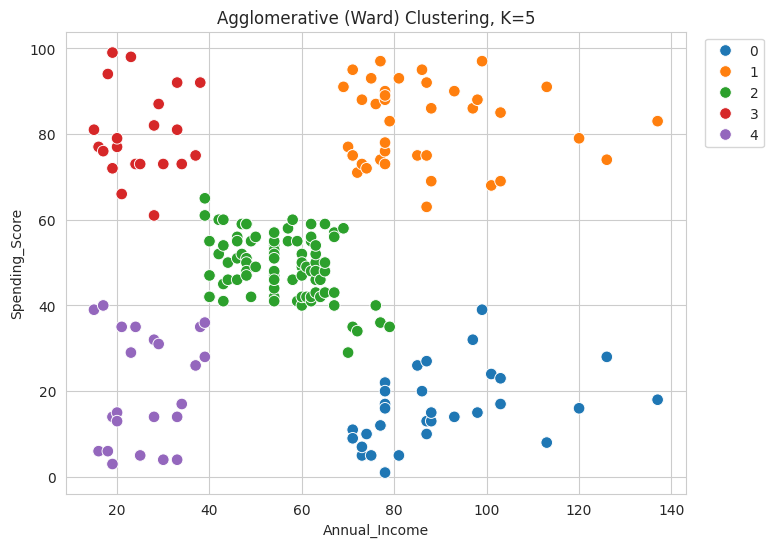

In [13]:
hc = AgglomerativeClustering(n_clusters=K, linkage='ward')
df['Hierarchical'] = hc.fit_predict(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Hierarchical', data=df, palette='tab10', s=70)
plt.title(f'Agglomerative (Ward) Clustering, K={K}'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.show()

## 7. Density-Based Methods
Clusters are dense regions separated by sparse regions. These methods do not need K, can find arbitrary shapes and label low-density points as **noise (-1)**.

### 7.1 DBSCAN
Parameters: `eps` (neighbourhood radius) and `min_samples`. We look at the **k-distance graph** and then grid-search for a sensible pair.

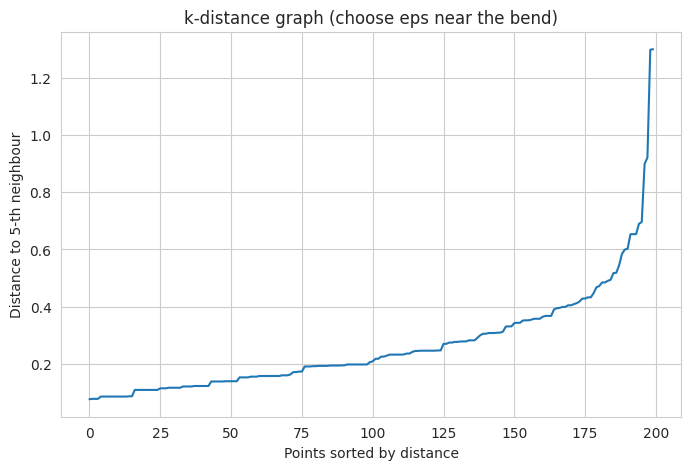

In [14]:
min_samples = 5
kd = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1])
plt.plot(kd); plt.title('k-distance graph (choose eps near the bend)')
plt.xlabel('Points sorted by distance'); plt.ylabel(f'Distance to {min_samples}-th neighbour'); plt.show()

In [15]:
grid = []
for eps in np.arange(0.2, 0.85, 0.05):
    for ms in [3, 4, 5, 6, 8]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        noise = (lab == -1).mean()
        if 2 <= n_cl <= 8 and noise <= 0.12:
            grid.append((round(eps, 2), ms, n_cl, round(noise, 3), silhouette_score(X[lab != -1], lab[lab != -1])))
g = pd.DataFrame(grid, columns=['eps', 'min_samples', 'clusters', 'noise_frac', 'silhouette']).sort_values('silhouette', ascending=False)
print(g.head(5).round(3).to_string(index=False))
eps_best, ms_best = g.iloc[0]['eps'], int(g.iloc[0]['min_samples'])
print(f'\nSelected eps={eps_best}, min_samples={ms_best}')

df['DBSCAN'] = DBSCAN(eps=eps_best, min_samples=ms_best).fit_predict(X)
print(df['DBSCAN'].value_counts().sort_index().to_dict(), '(-1 = noise)')

 eps  min_samples  clusters  noise_frac  silhouette
0.35            5         6       0.115       0.558
0.30            4         8       0.115       0.520
0.35            3         7       0.055       0.515
0.35            4         7       0.080       0.511
0.40            6         4       0.095       0.490

Selected eps=0.35, min_samples=5
{-1: 23, 0: 16, 1: 12, 2: 7, 3: 88, 4: 31, 5: 23} (-1 = noise)


### 7.2 OPTICS
OPTICS orders points by **reachability distance** so one fixed `eps` is not needed. Valleys in the reachability plot are clusters; cutting the plot at a horizontal line (red) extracts the clusters. (OPTICS can also extract clusters automatically with the `xi` method, but on this small dataset that labels almost half the customers as noise, so we use the cut-based extraction.)

{-1: 26, 0: 5, 1: 88, 2: 16, 3: 23, 4: 11, 5: 31} (-1 = noise)


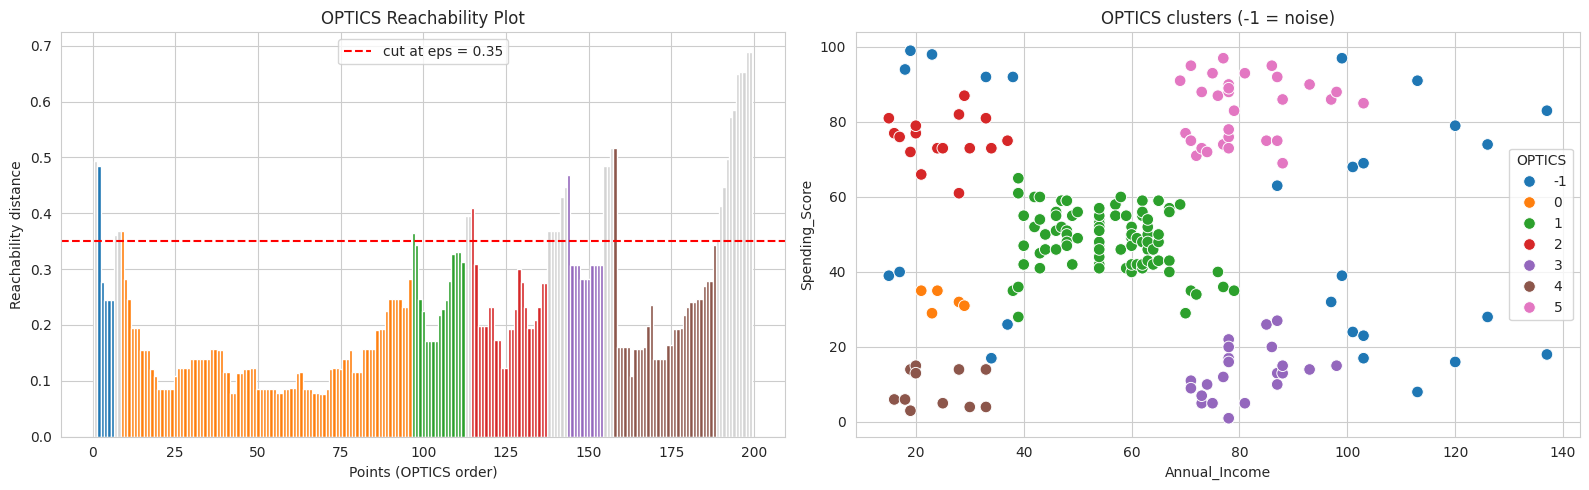

In [16]:
optics = OPTICS(min_samples=5, cluster_method='dbscan', eps=0.35)   # extract clusters by cutting the reachability plot at eps
df['OPTICS'] = optics.fit_predict(X)
print(df['OPTICS'].value_counts().sort_index().to_dict(), '(-1 = noise)')

reach = optics.reachability_[optics.ordering_]
lab_ord = optics.labels_[optics.ordering_]
cols = sns.color_palette('tab10', 10)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for l in np.unique(lab_ord):
    idx = np.where(lab_ord == l)[0]
    ax[0].bar(idx, np.where(np.isinf(reach[idx]), np.nan, reach[idx]), color='lightgrey' if l == -1 else cols[l % 10], width=1)
ax[0].axhline(0.35, color='red', ls='--', label='cut at eps = 0.35'); ax[0].legend()
ax[0].set(title='OPTICS Reachability Plot', xlabel='Points (OPTICS order)', ylabel='Reachability distance')
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='OPTICS', data=df, palette='tab10', s=70, ax=ax[1]); ax[1].set_title('OPTICS clusters (-1 = noise)')
plt.tight_layout(); plt.show()

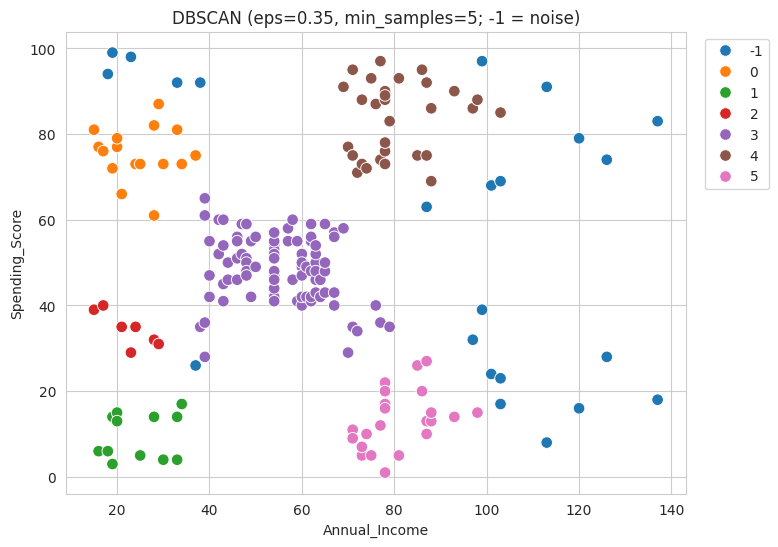

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='DBSCAN', data=df, palette='tab10', s=70)
plt.title(f'DBSCAN (eps={eps_best}, min_samples={ms_best}; -1 = noise)'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.show()

## 8. Evaluation of Clustering
Real data has **no ground-truth labels**, so we use evaluation methods that do not need them:

1. **Internal indices** – Silhouette ↑, Calinski-Harabasz ↑, Davies-Bouldin ↓ (noise points excluded).
2. **Stability** – re-cluster random 80 % subsamples; if the clusters are real, two subsamples agree (high ARI).
3. **Agreement between methods** – Adjusted Rand Index between every pair of methods. High agreement across very different algorithms is strong evidence the structure is genuine.

(When labels *are* available, external indices such as ARI, NMI and V-measure would be used.)

In [18]:
methods = ['KMeans', 'KMedoids', 'Hierarchical', 'DBSCAN', 'OPTICS']
rows = []
for m in methods:
    lab = df[m].values; core = lab != -1
    rows.append({'Method': m, 'Clusters': len(set(lab[core])), 'Noise pts': int((~core).sum()),
                 'Silhouette': silhouette_score(X[core], lab[core]),
                 'Calinski-Harabasz': calinski_harabasz_score(X[core], lab[core]),
                 'Davies-Bouldin': davies_bouldin_score(X[core], lab[core])})
res = pd.DataFrame(rows).set_index('Method').round(3)
res.style.background_gradient(cmap='YlGn', subset=['Silhouette', 'Calinski-Harabasz']).background_gradient(cmap='YlGn_r', subset=['Davies-Bouldin'])

,Clusters,Noise pts,Silhouette,Calinski-Harabasz,Davies-Bouldin
Method,,,,,
KMeans,5,0,0.555000,248.649000,0.572000
KMedoids,5,0,0.547000,244.111000,0.587000
Hierarchical,5,0,0.554000,244.410000,0.578000
DBSCAN,6,23,0.558000,245.356000,0.511000
OPTICS,6,26,0.552000,237.675000,0.490000


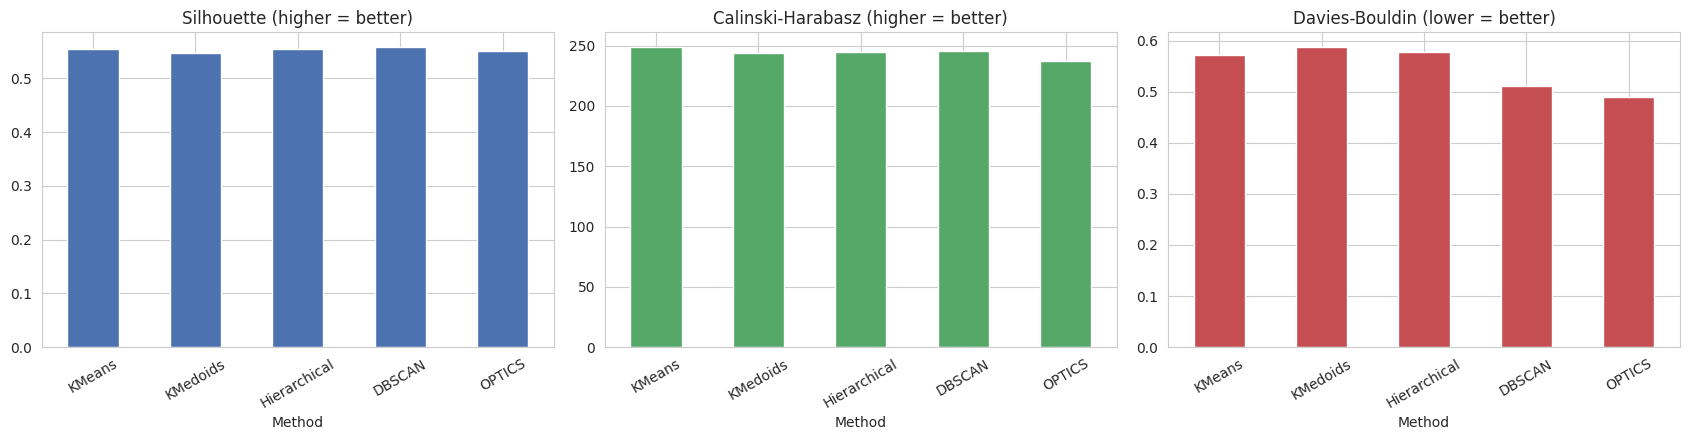

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
res['Silhouette'].plot.bar(ax=ax[0], color='#4C72B0', rot=30); ax[0].set_title('Silhouette (higher = better)')
res['Calinski-Harabasz'].plot.bar(ax=ax[1], color='#55A868', rot=30); ax[1].set_title('Calinski-Harabasz (higher = better)')
res['Davies-Bouldin'].plot.bar(ax=ax[2], color='#C44E52', rot=30); ax[2].set_title('Davies-Bouldin (lower = better)')
plt.tight_layout(); plt.show()

**Note:** DBSCAN/OPTICS drop their noise points before scoring, which flatters their internal indices, so compare them with care.

In [20]:
# Stability: ARI between clusterings of two random 80% subsamples, on the points they share
fits = {
    'KMeans':       lambda Z: KMeans(K, n_init=10, random_state=0).fit_predict(Z),
    'KMedoids':     lambda Z: kmedoids(Z, K, n_init=5)[0],
    'Hierarchical': lambda Z: AgglomerativeClustering(K, linkage='ward').fit_predict(Z),
    'DBSCAN':       lambda Z: DBSCAN(eps=eps_best, min_samples=ms_best).fit_predict(Z)}

r = np.random.default_rng(0); stab = {}
for name, f in fits.items():
    scores = []
    for _ in range(20):
        a = np.sort(r.choice(len(X), int(0.8 * len(X)), replace=False))
        b = np.sort(r.choice(len(X), int(0.8 * len(X)), replace=False))
        la, lb = dict(zip(a, f(X[a]))), dict(zip(b, f(X[b])))
        common = np.intersect1d(a, b)
        scores.append(adjusted_rand_score([la[i] for i in common], [lb[i] for i in common]))
    stab[name] = (np.mean(scores), np.std(scores))
stab = pd.DataFrame(stab, index=['Mean ARI', 'Std']).T.round(3)
stab

,Mean ARI,Std
KMeans,0.984,0.016
KMedoids,0.736,0.094
Hierarchical,0.936,0.065
DBSCAN,0.897,0.052


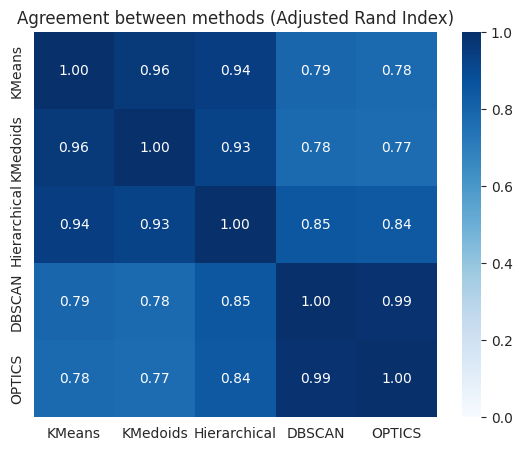

In [21]:
# Agreement between methods (ARI matrix)
agree = pd.DataFrame([[adjusted_rand_score(df[a], df[b]) for b in methods] for a in methods], index=methods, columns=methods)
plt.figure(figsize=(6.5, 5)); sns.heatmap(agree, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Agreement between methods (Adjusted Rand Index)'); plt.show()

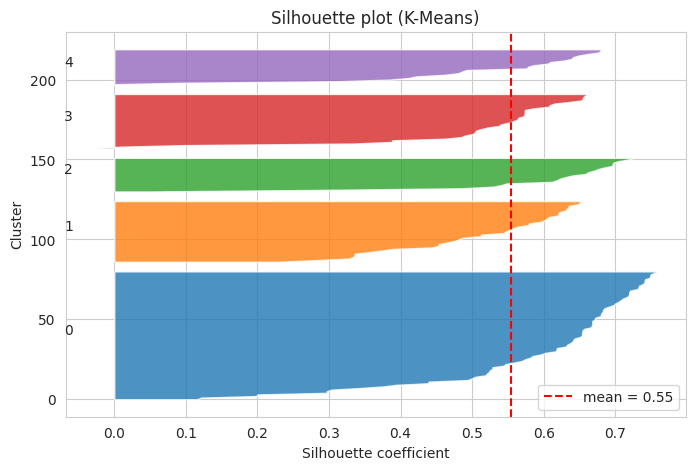

In [22]:
sv = silhouette_samples(X, df['KMeans']); y = 0
plt.figure(figsize=(8, 5))
for c in range(K):
    v = np.sort(sv[df['KMeans'] == c]); plt.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=.8); plt.text(-0.07, y + len(v) / 2, str(c)); y += len(v) + 5
plt.axvline(sv.mean(), color='red', ls='--', label=f'mean = {sv.mean():.2f}')
plt.title('Silhouette plot (K-Means)'); plt.xlabel('Silhouette coefficient'); plt.ylabel('Cluster'); plt.legend(); plt.show()

## 9. Outlier Detection Methods
There is no answer key for real outliers, so we apply one method from each family in the syllabus and then see **where they agree**.

| Family | Method |
|---|---|
| Statistical | Z-score (|z| > 3), IQR rule, Mahalanobis distance (χ² cut-off) |
| Distance / clustering-based | Distance to own K-Means centroid (IQR rule) |
| Density-based | DBSCAN noise points, Local Outlier Factor (LOF) |
| Isolation-based | Isolation Forest |

In [23]:
flags = pd.DataFrame(index=df.index)

# Statistical 1: Z-score on any feature
flags['Z-score'] = (np.abs(X) > 3).any(axis=1).astype(int)

# Statistical 2: IQR rule on any feature (Q1 - 1.5 IQR, Q3 + 1.5 IQR)
q1, q3 = df[features].quantile(.25), df[features].quantile(.75); iqr = q3 - q1
flags['IQR'] = ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).any(axis=1).astype(int)

# Statistical 3: Mahalanobis distance (multivariate), flag if D^2 > chi-square 97.5% quantile
cov_inv = np.linalg.inv(np.cov(X.T))
d2 = np.einsum('ij,jk,ik->i', X - X.mean(0), cov_inv, X - X.mean(0))
flags['Mahalanobis'] = (d2 > chi2.ppf(0.975, df=X.shape[1])).astype(int)

# Distance / clustering-based: distance to own K-Means centroid, IQR rule
dist = np.linalg.norm(X - kmeans.cluster_centers_[df['KMeans']], axis=1)
a, b = np.percentile(dist, [25, 75])
flags['KMeans-distance'] = (dist > b + 1.5 * (b - a)).astype(int)

# Density-based: DBSCAN noise and LOF
flags['DBSCAN-noise'] = (df['DBSCAN'] == -1).astype(int)
flags['LOF'] = (LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(X) == -1).astype(int)

# Isolation-based
flags['IsolationForest'] = (IsolationForest(contamination=0.05, random_state=42).fit_predict(X) == -1).astype(int)

pd.DataFrame({'Points flagged': flags.sum()})

,Points flagged
Z-score,0
IQR,2
Mahalanobis,2
KMeans-distance,6
DBSCAN-noise,23
LOF,10
IsolationForest,10


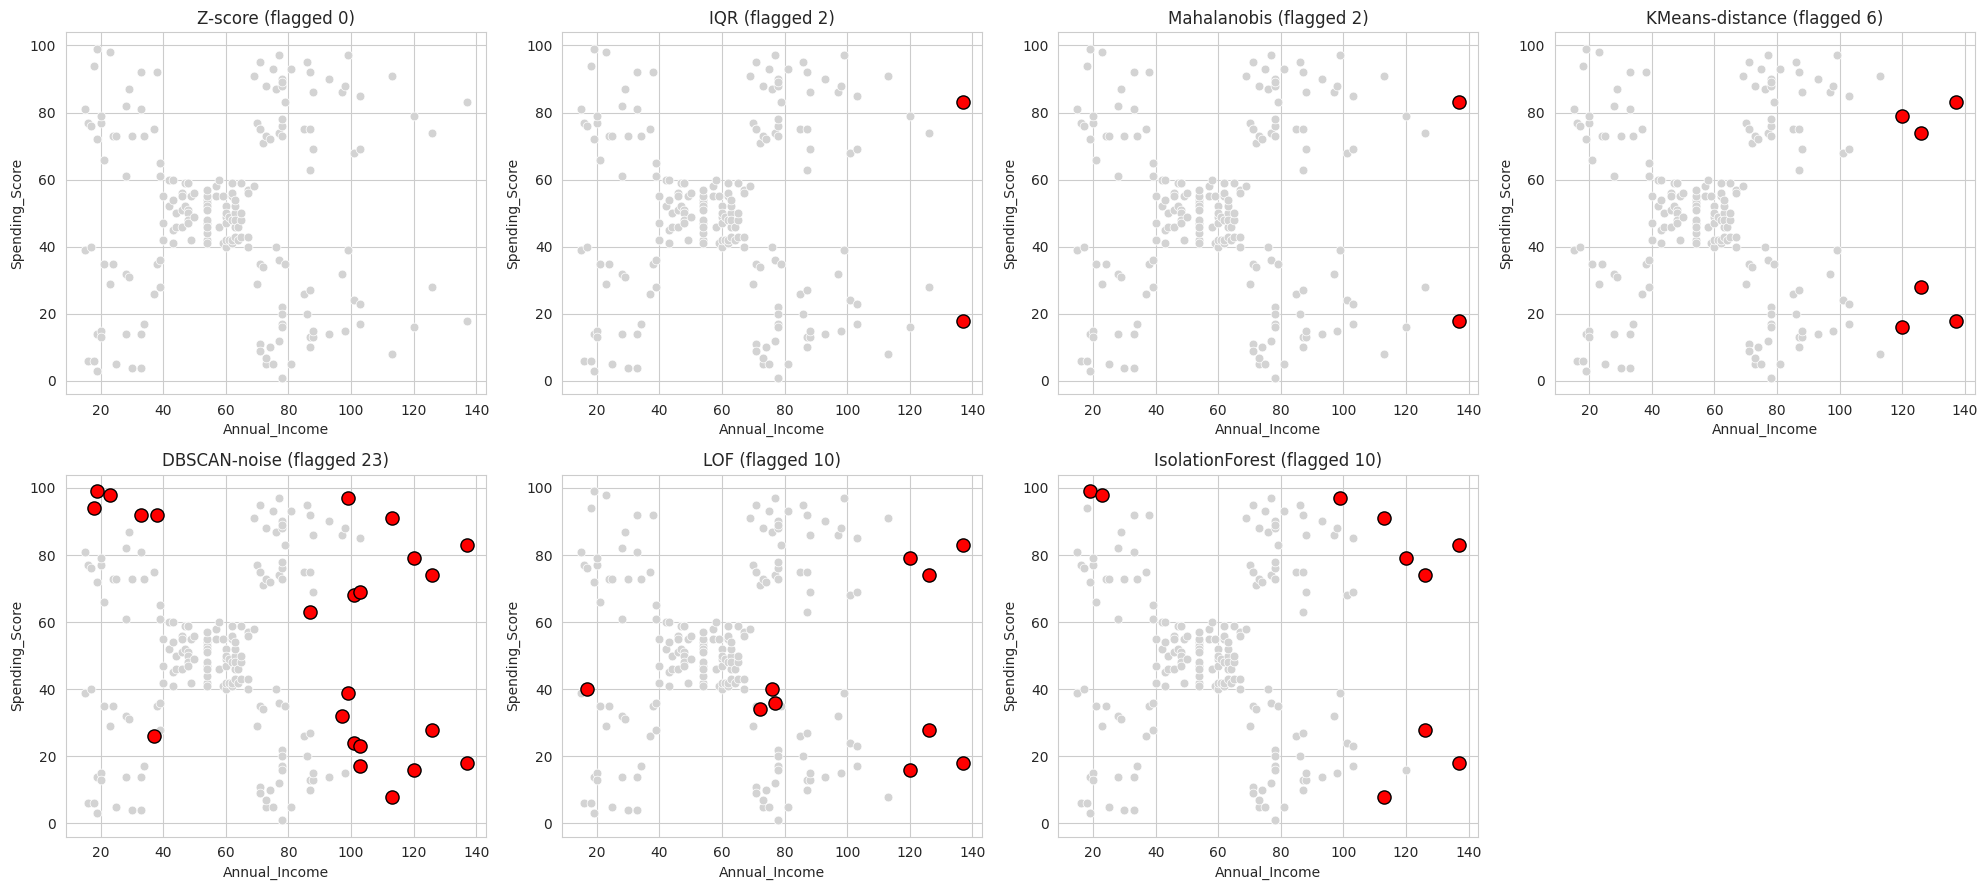

In [24]:
fig, ax = plt.subplots(2, 4, figsize=(20, 9)); ax = ax.ravel()
for a_, c in zip(ax, flags.columns):
    sns.scatterplot(x=df['Annual_Income'], y=df['Spending_Score'], color='lightgrey', s=40, ax=a_)
    f = flags[c] == 1
    a_.scatter(df.loc[f, 'Annual_Income'], df.loc[f, 'Spending_Score'], c='red', s=90, edgecolor='k')
    a_.set_title(f'{c} (flagged {int(f.sum())})')
ax[-1].axis('off')
plt.tight_layout(); plt.show()

### 9.1 Agreement and consensus
How similar are the detectors? (Jaccard overlap of the points they flag.) A customer flagged by **at least 3 methods** is treated as a consensus outlier, which reduces false alarms from any single method.

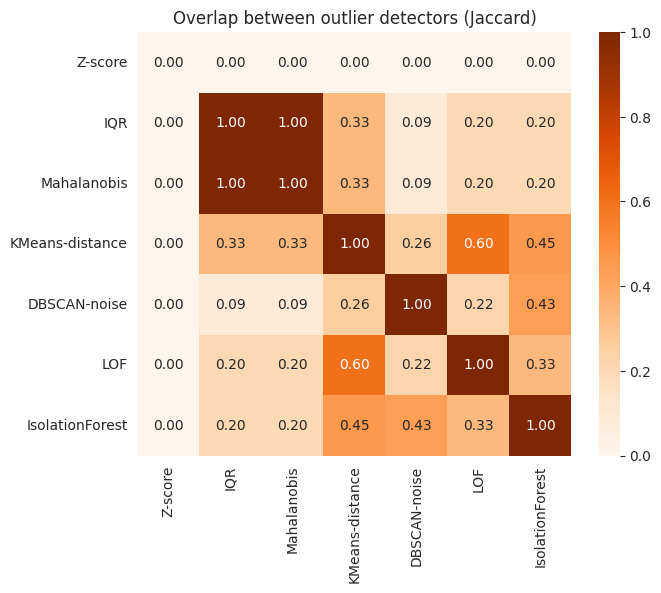

Consensus outliers (>= 3 votes): 6


,CustomerID,Gender,Age,Annual_Income,Spending_Score,Votes,Outlier
198,199,Male,32,137,18,6,1
199,200,Male,30,137,83,6,1
195,196,Female,35,120,79,4,1
196,197,Female,45,126,28,4,1
197,198,Male,32,126,74,4,1
194,195,Female,47,120,16,3,1
11,12,Female,35,19,99,2,0
185,186,Male,30,99,97,2,0
19,20,Female,35,23,98,2,0
192,193,Male,33,113,8,2,0


In [25]:
cols_ = flags.columns
jac = pd.DataFrame([[ (flags[a].values & flags[b].values).sum() / max((flags[a].values | flags[b].values).sum(), 1) for b in cols_] for a in cols_], index=cols_, columns=cols_)
plt.figure(figsize=(7, 5.5)); sns.heatmap(jac, annot=True, fmt='.2f', cmap='Oranges'); plt.title('Overlap between outlier detectors (Jaccard)'); plt.show()

df['Votes'] = flags.sum(axis=1)
df['Outlier'] = (df['Votes'] >= 3).astype(int)
print('Consensus outliers (>= 3 votes):', int(df['Outlier'].sum()))
df.loc[df['Votes'] >= 2, ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score', 'Votes', 'Outlier']].sort_values('Votes', ascending=False)

## 10. Final Model after Outlier Removal
We remove the consensus outliers, re-scale and re-run **K-Means**. We then compare quality before and after.

In [26]:
clean = df[df['Outlier'] == 0].copy().reset_index(drop=True)
scaler2 = StandardScaler()
Xc = scaler2.fit_transform(clean[features])

final = KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=42).fit(Xc)
clean['Segment'] = final.labels_

pd.DataFrame({
    'Before (all customers)': [silhouette_score(X, df['KMeans']), davies_bouldin_score(X, df['KMeans']), calinski_harabasz_score(X, df['KMeans'])],
    'After (outliers removed)': [silhouette_score(Xc, clean['Segment']), davies_bouldin_score(Xc, clean['Segment']), calinski_harabasz_score(Xc, clean['Segment'])]},
    index=['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz']).round(3)

,Before (all customers),After (outliers removed)
Silhouette,0.555,0.569
Davies-Bouldin,0.572,0.557
Calinski-Harabasz,248.649,286.952


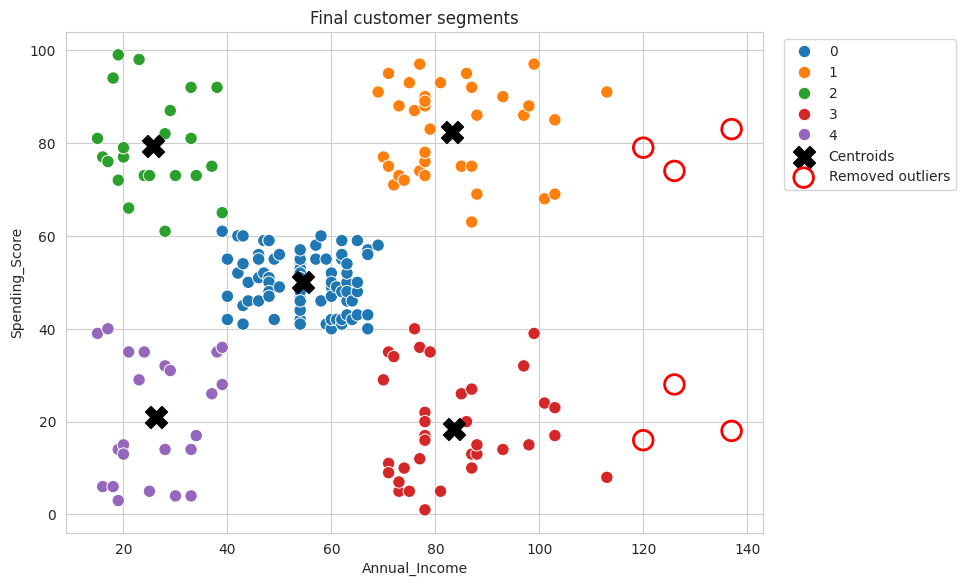

In [27]:
plt.figure(figsize=(9, 6.5))
sns.scatterplot(x='Annual_Income', y='Spending_Score', hue='Segment', data=clean, palette='tab10', s=80)
cc = scaler2.inverse_transform(final.cluster_centers_)
plt.scatter(cc[:, 0], cc[:, 1], c='black', marker='X', s=250, label='Centroids')
o = df[df['Outlier'] == 1]
plt.scatter(o['Annual_Income'], o['Spending_Score'], facecolors='none', edgecolors='red', s=200, linewidths=2, label='Removed outliers')
plt.title('Final customer segments'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.show()

## 11. Segment Profiling and Business Insights
Here Age and Gender, which were *not* used for clustering, help describe each segment.

In [28]:
profile = clean.groupby('Segment').agg(Customers=('CustomerID', 'count'), Avg_Age=('Age', 'mean'),
                                       Avg_Income=('Annual_Income', 'mean'), Avg_Spending=('Spending_Score', 'mean'),
                                       Female_pct=('Gender', lambda s: 100 * (s == 'Female').mean())).round(1)
inc_med, sp_med = profile['Avg_Income'].median(), profile['Avg_Spending'].median()

def name_segment(r):
    hi_i, lo_i = r.Avg_Income > inc_med + 10, r.Avg_Income < inc_med - 10
    hi_s, lo_s = r.Avg_Spending > sp_med + 10, r.Avg_Spending < sp_med - 10
    if hi_i and hi_s: return 'Premium / VIP', 'Loyalty programs, early access, premium product launches'
    if hi_i and lo_s: return 'Careful Spenders', 'Quality-focused campaigns and personalised offers to raise engagement'
    if lo_i and hi_s: return 'Trendy Spenders', 'Discounts, EMI / cashback offers, social-media campaigns'
    if lo_i and lo_s: return 'Budget Customers', 'Value deals, clearance sales, low-cost retention'
    return 'Standard Customers', 'General promotions, seasonal offers, upsell nudges'

profile[['Name', 'Strategy']] = profile.apply(lambda r: pd.Series(name_segment(r)), axis=1)
clean['Segment_Name'] = clean['Segment'].map(profile['Name'])
profile

,Customers,Avg_Age,Avg_Income,Avg_Spending,Female_pct,Name,Strategy
Segment,,,,,,,
0,78,43.1,54.6,50.0,59.0,Standard Customers,"General promotions, seasonal offers, upsell nu..."
1,36,32.7,83.1,82.4,55.6,Premium / VIP,"Loyalty programs, early access, premium produc..."
2,22,25.3,25.7,79.4,59.1,Trendy Spenders,"Discounts, EMI / cashback offers, social-media..."
3,35,40.3,83.5,18.5,45.7,Careful Spenders,Quality-focused campaigns and personalised off...
4,23,45.2,26.3,20.9,60.9,Budget Customers,"Value deals, clearance sales, low-cost retention"


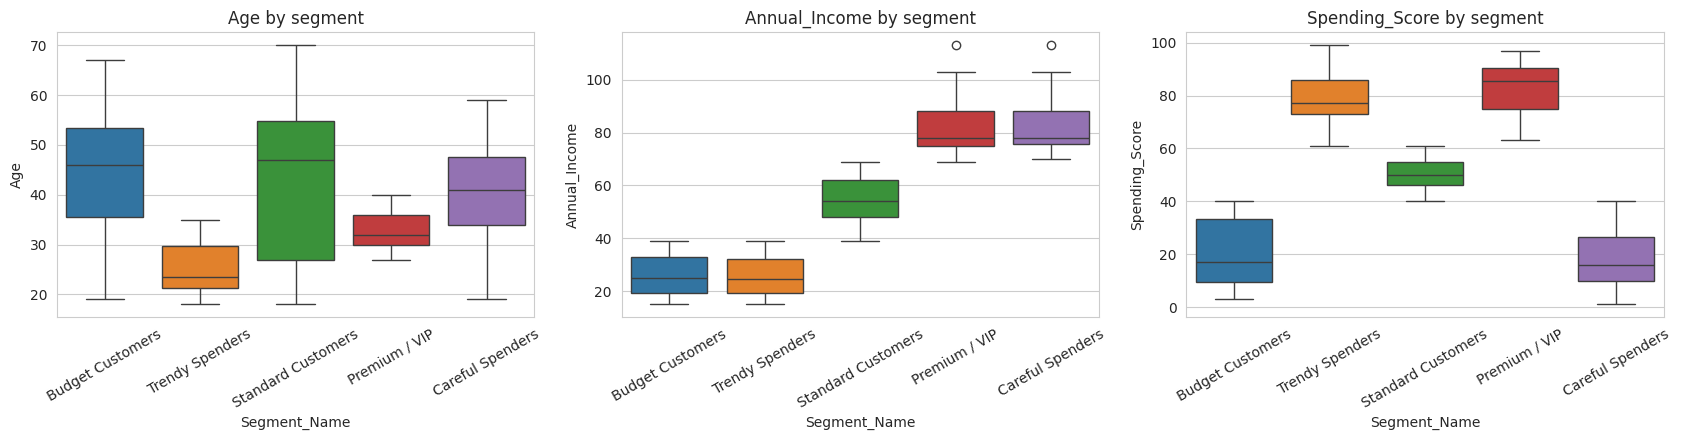

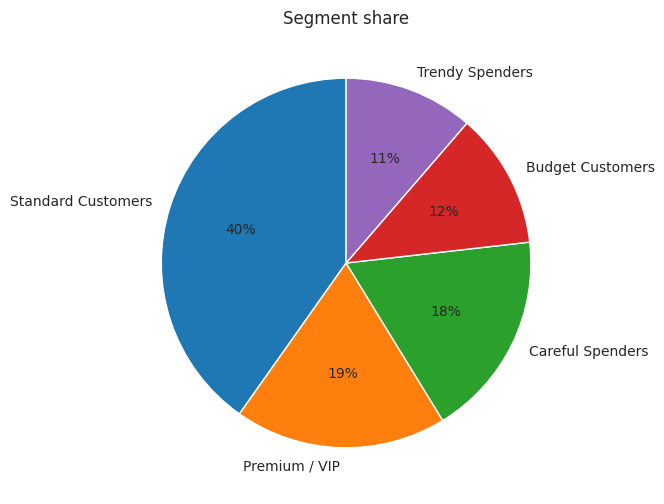

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a_, col in zip(ax, ['Age', 'Annual_Income', 'Spending_Score']):
    sns.boxplot(x='Segment_Name', y=col, data=clean, palette='tab10', ax=a_); a_.set_title(f'{col} by segment'); a_.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 6))
clean['Segment_Name'].value_counts().plot.pie(autopct='%1.0f%%', startangle=90); plt.ylabel(''); plt.title('Segment share'); plt.show()

In [30]:
def predict_segment(income, spending):
    s = int(final.predict(scaler2.transform(pd.DataFrame([[income, spending]], columns=features)))[0])
    return profile.loc[s, 'Name'], profile.loc[s, 'Strategy']

print('Income 85k, Spending 80 ->', predict_segment(85, 80))
print('Income 20k, Spending 15 ->', predict_segment(20, 15))

clean.to_csv('customer_segments.csv', index=False)
# from google.colab import files; files.download('customer_segments.csv')
print('Saved customer_segments.csv')

Income 85k, Spending 80 -> ('Premium / VIP', 'Loyalty programs, early access, premium product launches')
Income 20k, Spending 15 -> ('Budget Customers', 'Value deals, clearance sales, low-cost retention')
Saved customer_segments.csv


## 12. Conclusion
- The Hopkins statistic confirmed the Mall Customers data has real cluster structure.
- **Partitioning:** K-Means and K-Medoids split customers into five groups. K-Medoids uses real customers as centres, so it is less affected by extreme points.
- **Hierarchical:** the dendrogram supported K = 5, and Ward linkage gave compact clusters while single linkage showed the chaining effect.
- **Density-based:** DBSCAN and OPTICS found clusters without being told K and set unusual customers aside as noise, but they depend on `eps` / `min_samples`.
- **Evaluation:** internal indices, subsample stability and agreement between methods all point to the same five segments.
- **Outlier detection:** statistical, distance, density and isolation-based detectors were compared; consensus voting gave a more reliable outlier list than any single method.
- **Business value:** each segment received a name and a marketing strategy (VIP loyalty, trend-based discounts, engagement campaigns, value deals, etc.).

**Limitations:** only 200 customers and two clustering features; Spending Score is a mall-assigned index, not real purchase data.
**Future scope:** add Age and purchase history, try Gaussian Mixture Models / BIRCH, and build a Streamlit dashboard.

**References:** Han, Kamber & Pei – *Data Mining: Concepts and Techniques*; scikit-learn documentation; Kaggle "Customer Segmentation Tutorial in Python" (Mall Customers dataset).
